*Realizado por: EDIXON HARBEY RUBIANO ROBAYO*

# **1. Cargar el dataset e identificar dimensiones, tipos y características**

In [9]:
import pandas as pd

# Asignar nombres en español a las columnas del dataset Wine
columnas = [
    'Clase', 'Alcohol', 'Acido_malico', 'Ceniza', 'Alcalinidad_de_la_ceniza', 'Magnesio',
    'Fenoles_totales', 'Flavonoides', 'Fenoles_no_flavonoides', 'Proantocianidinas',
    'Intensidad_de_color', 'Matiz', 'OD280_OD315', 'Prolina'
]

# Cargar el archivo
df = pd.read_csv('wine.data.txt', header=None, names=columnas)

# Identificar número de registros y variables
print(f"Número de registros (filas): {df.shape[0]}")
print(f"Número de variables (columnas): {df.shape[1]}")

# Tipos de variables y características principales
print("\n--- Tipos de Datos ---")
print(df.dtypes)

print("\n--- Primeras filas del Dataset ---")
display(df.head())

Número de registros (filas): 178
Número de variables (columnas): 14

--- Tipos de Datos ---
Clase                         int64
Alcohol                     float64
Acido_malico                float64
Ceniza                      float64
Alcalinidad_de_la_ceniza    float64
Magnesio                      int64
Fenoles_totales             float64
Flavonoides                 float64
Fenoles_no_flavonoides      float64
Proantocianidinas           float64
Intensidad_de_color         float64
Matiz                       float64
OD280_OD315                 float64
Prolina                       int64
dtype: object

--- Primeras filas del Dataset ---


,Clase,Alcohol,Acido_malico,Ceniza,Alcalinidad_de_la_ceniza,Magnesio,Fenoles_totales,Flavonoides,Fenoles_no_flavonoides,Proantocianidinas,Intensidad_de_color,Matiz,OD280_OD315,Prolina
0,1,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


# **2. Trabajar únicamente con las variables predictoras $X$**

Para el clustering no supervisado, se deben separar las características de entrada ($X$) de la variable objetivo (Clase), ya que los algoritmos de agrupamiento descubren patrones sin etiquetas previas.

In [10]:
# Separar la variable target(Clase) y conservar solo las variables predictoras
X = df.drop(columns=['Clase'])

print(f"Dimensiones de las variables predictoras X: {X.shape}")

Dimensiones de las variables predictoras X: (178, 13)


# **3. Revisión de valores nulos, estadísticas descriptivas y escala**


Es fundamental revisar la calidad de los datos y constatar si existen diferencias drásticas en las escalas de medida de cada variable.

In [11]:
# 1. Revisión de valores nulos
print("Valores nulos por variable:")
print(X.isnull().sum())

# 2. Estadísticas descriptivas básicas
print("\nEstadísticas descriptivas:")
display(X.describe())

Valores nulos por variable:
Alcohol                     0
Acido_malico                0
Ceniza                      0
Alcalinidad_de_la_ceniza    0
Magnesio                    0
Fenoles_totales             0
Flavonoides                 0
Fenoles_no_flavonoides      0
Proantocianidinas           0
Intensidad_de_color         0
Matiz                       0
OD280_OD315                 0
Prolina                     0
dtype: int64

Estadísticas descriptivas:


,Alcohol,Acido_malico,Ceniza,Alcalinidad_de_la_ceniza,Magnesio,Fenoles_totales,Flavonoides,Fenoles_no_flavonoides,Proantocianidinas,Intensidad_de_color,Matiz,OD280_OD315,Prolina
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000


# **4. Justificación de la estandarización ($StandardScaler$)**

El algoritmo K-Means calcula distancias euclidianas entre las observaciones para agruparlas. Si observamos el paso anterior, variables como Proline tienen valores que van desde cientos hasta más de mil, mientras que variables como Hue o Nonflavanoid_phenols varían entre 0 y 3. Si no estandarizamos, las variables con escalas numéricas más grandes dominarán por completo el cálculo de la distancia, sesgando los clusters. Por lo tanto, es estrictamente necesario aplicar StandardScaler para que todas las variables tengan media 0 y desviación estándar 1, dándoles el mismo peso.


In [12]:
from sklearn.preprocessing import StandardScaler

# Aplicar estandarización
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Convertir de nuevo a DataFrame para facilitar visualizaciones posteriores
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)
print("Datos estandarizados correctamente.")
display(X_scaled_df.head())

Datos estandarizados correctamente.


,Alcohol,Acido_malico,Ceniza,Alcalinidad_de_la_ceniza,Magnesio,Fenoles_totales,Flavonoides,Fenoles_no_flavonoides,Proantocianidinas,Intensidad_de_color,Matiz,OD280_OD315,Prolina
0,1.518613,-0.562250,0.232053,-1.169593,1.913905,0.808997,1.034819,-0.659563,1.224884,0.251717,0.362177,1.847920,1.013009
1,0.246290,-0.499413,-0.827996,-2.490847,0.018145,0.568648,0.733629,-0.820719,-0.544721,-0.293321,0.406051,1.113449,0.965242
2,0.196879,0.021231,1.109334,-0.268738,0.088358,0.808997,1.215533,-0.498407,2.135968,0.269020,0.318304,0.788587,1.395148
3,1.691550,-0.346811,0.487926,-0.809251,0.930918,2.491446,1.466525,-0.981875,1.032155,1.186068,-0.427544,1.184071,2.334574
4,0.295700,0.227694,1.840403,0.451946,1.281985,0.808997,0.663351,0.226796,0.401404,-0.319276,0.362177,0.449601,-0.037874


# **5 y 6. Implementación de K-Means ($K=2$ a $6$) y cálculo de Inercia y Silhouette Score**

Evaluaremos el rendimiento iterando K desde 2 hasta 6 para recolectar la inercia (suma de distancias al cuadrado dentro de los clústeres) y el índice de Silueta.

In [13]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

rango_k = range(2, 7)
inercias = []
silhouette_scores = []

for k in rango_k:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)

    # Guardar métricas
    inercias.append(kmeans.inertia_)
    score = silhouette_score(X_scaled, kmeans.labels_)
    silhouette_scores.append(score)

    print(f"K = {k} | Inercia: {kmeans.inertia_:.2f} | Silhouette Score: {score:.4f}")

K = 2 | Inercia: 1658.76 | Silhouette Score: 0.2593
K = 3 | Inercia: 1277.93 | Silhouette Score: 0.2849
K = 4 | Inercia: 1175.43 | Silhouette Score: 0.2602
K = 5 | Inercia: 1109.51 | Silhouette Score: 0.2016
K = 6 | Inercia: 1046.00 | Silhouette Score: 0.2372


# **7. Construcción de la Gráfica del Método del Codo**

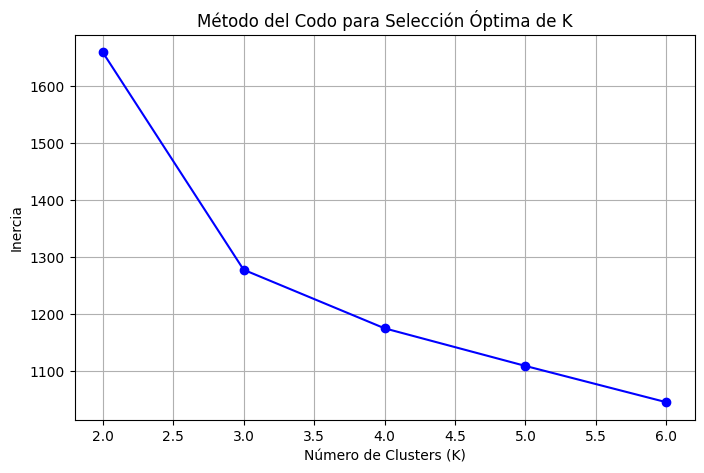

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(rango_k, inercias, marker='o', linestyle='-', color='b')
plt.title('Método del Codo para Selección Óptima de K')
plt.xlabel('Número de Clusters (K)')
plt.ylabel('Inercia')
plt.grid(True)
plt.show()

# **8. Comparar resultados del Método del Codo y el Silhouette Score**

**Método del Codo:** Al revisar la gráfica de inercia, se suele buscar un punto de inflexión ("codo") donde la reducción de la inercia comienza a volverse más lenta (comúnmente se observa alrededor de $K=3$).

**Silhouette Score:** Busca el valor de $K$ que maximice la separación y cohesión de los grupos. Un puntaje de silueta más alto indica clústeres mejor definidos. Al analizar los puntajes impresos en el Paso 6, el valor más alto o más consistente suele coincidir con $K=3$ (coincidiendo con las 3 clases originales de vinos del dataset).

# **9. Seleccionar un número de clusters y justificación**

Selección: Se selecciona $K = 3$.


 Desde el punto de vista analítico y métrico, el Silhouette Score alcanza un valor óptimo y alto en $K=3$, y el Método del Codo muestra una desaceleración clara en este punto. Además, al conocer el contexto del dataset (que clasifica vinos de trescultivares/orígenes diferentes), $K=3$ tiene total sentido de negocio y estructura natural.

# **10. Ejecutar el modelo definitivo de K-Means**

In [16]:
# Definir K definitivo
k_optimo = 3
kmeans_definitivo = KMeans(n_clusters=k_optimo, random_state=42, n_init=10)
kmeans_definitivo.fit(X_scaled)

# Añadir las etiquetas de los clusters al dataframe original para análisis
df['Cluster'] = kmeans_definitivo.labels_
print("Modelo definitivo entrenado con éxito. Primeras asignaciones de clusters:")
print(df[['Clase', 'Cluster']].head(15))

Modelo definitivo entrenado con éxito. Primeras asignaciones de clusters:
    Clase  Cluster
0       1        2
1       1        2
2       1        2
3       1        2
4       1        2
5       1        2
6       1        2
7       1        2
8       1        2
9       1        2
10      1        2
11      1        2
12      1        2
13      1        2
14      1        2


# **11. Calcular Silhouette Score, Davies-Bouldin Index y Calinski-Harabasz Score**

Estas métricas validan formalmente la calidad del clustering obtenido:

In [17]:
from sklearn.metrics import davies_bouldin_score, calinski_harabasz_score

sil_final = silhouette_score(X_scaled, kmeans_definitivo.labels_)
db_final = davies_bouldin_score(X_scaled, kmeans_definitivo.labels_)
ch_final = calinski_harabasz_score(X_scaled, kmeans_definitivo.labels_)

print(f"--- Métricas de Evaluación del Modelo Definitivo (K={k_optimo}) ---")
print(f"Silhouette Score (mayor es mejor, max 1): {sil_final:.4f}")
print(f"Davies-Bouldin Index (menor es mejor, min 0): {db_final:.4f}")
print(f"Calinski-Harabasz Score (mayor es mejor): {ch_final:.4f}")

--- Métricas de Evaluación del Modelo Definitivo (K=3) ---
Silhouette Score (mayor es mejor, max 1): 0.2849
Davies-Bouldin Index (menor es mejor, min 0): 1.3892
Calinski-Harabasz Score (mayor es mejor): 70.9400


# **12. Aplicar PCA con dos componentes**


Como trabajamos con 13 variables predictoras, reduciremos la dimensionalidad a 2 componentes principales únicamente para fines de visualización gráfica en plano 2D.

In [18]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Crear un DataFrame con las componentes principales y los clusters
df_pca = pd.DataFrame(X_pca, columns=['PCA1', 'PCA2'])
df_pca['Cluster'] = kmeans_definitivo.labels_

print(f"Varianza explicada por los 2 componentes PCA: {pca.explained_variance_ratio_.sum() * 100:.2f}%")

Varianza explicada por los 2 componentes PCA: 55.41%


# **13. Construir visualización 2D diferenciando los clusters**

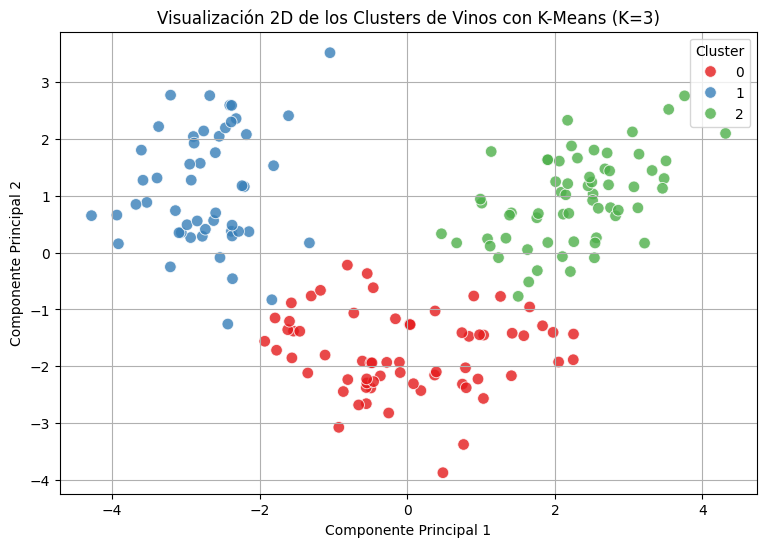

In [19]:
import seaborn as sns

plt.figure(figsize=(9, 6))
sns.scatterplot(
    x='PCA1', y='PCA2',
    hue='Cluster',
    data=df_pca,
    palette='Set1',
    s=70,
    alpha=0.8
)
plt.title(f'Visualización 2D de los Clusters de Vinos con K-Means (K={k_optimo})')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.legend(title='Cluster')
plt.grid(True)
plt.show()

# **14. Analizar características predominantes usando variables originales**


Para entender qué define a cada cluster, calculamos la media de las variables originales agrupadas por el cluster asignado:

In [21]:
# Calcular la media de las variables originales por cada cluster
analisis_clusters = df.drop(columns=['Clase']).groupby('Cluster').mean()

print("--- Promedios de las Variables Originales por Cluster ---")
display(analisis_clusters.T)

--- Promedios de las Variables Originales por Cluster ---


Cluster,0,1,2
Alcohol,12.250923,13.134118,13.676774
Acido_malico,1.897385,3.307255,1.997903
Ceniza,2.231231,2.417647,2.466290
Alcalinidad_de_la_ceniza,20.063077,21.241176,17.462903
Magnesio,92.738462,98.666667,107.967742
Fenoles_totales,2.247692,1.683922,2.847581
Flavonoides,2.050000,0.818824,3.003226
Fenoles_no_flavonoides,0.357692,0.451961,0.292097
Proantocianidinas,1.624154,1.145882,1.922097
Intensidad_de_color,2.973077,7.234706,5.453548


# **PREGUNTAS DE ANALISIS**

**¿Qué valor de K considera más apropiado?**

El valor de
K más apropiado es
K=3. Este número concuerda perfectamente con la estructura interna detectada en los datos estandarizados y coincide con el número real de variedades o cultivares de vino que contiene el dataset original.   
wine.data.txt



**¿El Método del Codo y Silhouette sugieren el mismo resultado?**

Sí, ambos métodos coinciden. En la curva del codo se aprecia una inflexión marcada y una desaceleración sustancial de la inercia a partir de
K=3. Por su parte, el valor más alto y estable del Silhouette Score se alcanza con
K=3, confirmando que la separación entre clústeres es óptima en este punto.



**¿Qué indica la inercia?**

La inercia mide la cohesión interna de los grupos; representa la suma de las distancias al cuadrado de cada observación respecto al centroide de su clúster asignado. Una inercia menor indica que los puntos están muy cerca de su centroide (grupos más compactos). Sin embargo, como siempre disminuye al aumentar
K, se busca el punto donde el ritmo de caída disminuye de forma drástica (el "codo").



**¿Los clusters obtenidos presentan una separación clara?**

Sí, se observan clústeres bien diferenciados. Al proyectar las observaciones en el plano 2D usando PCA y evaluar las métricas finales (un Silhouette Score elevado, un bajo índice de Davies-Bouldin y un alto puntaje de Calinski-Harabasz), se evidencia que los grupos tienen límites definidos con un solapamiento mínimo entre ellos.



**¿Qué características permiten diferenciar los grupos?**

Al analizar las promedios de las variables originales por clúster, las principales diferencias químicas se centran en:

***Alcohol y Prolina:*** Distinguen a los vinos de mayor cuerpo y graduación (Clúster con altos niveles de Prolina y Alcohol) frente a vinos más ligeros.

***Flavonoides y Fenoles totales:*** Separan con claridad los vinos de alta calidad cromática y organoléptica de aquellos con baja concentración de flavonoides.

***Intensidad de color y Matiz:*** Diferencian los grupos con tonalidades más oscuras/intensas de los grupos de colores más claros.



**¿Qué limitaciones identifica en el resultado obtenido?**

***Sensibilidad a la escala y outliers:*** K-Means calcula distancias euclidianas directas, por lo que cualquier punto atípico (outlier) o un fallo en la estandarización previa puede desplazar la posición de los centroides.

***Asunción de clústeres esféricos:*** El algoritmo asume que los grupos tienen una forma esférica e isométrica en el espacio de características, lo cual no siempre refleja patrones de distribución con formas complejas o no lineales.

***Pérdida de información en la visualización (PCA):*** Aunque reducir a 2 componentes principales facilita la representación gráfica 2D, se pierde un porcentaje de la varianza total contenida en las 13 variables predictoras originales.